In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks, argrelmax, find_peaks_cwt
from scipy import sparse
from scipy.sparse.linalg import spsolve
%matplotlib inline

In [670]:
sample = '031123A-13.5mM'

In [671]:
# get current working directory from for example fig1.py :
HERE_PATH = os.getcwd()

# get absolute path to the root folder in which whole project resides:
ROOT_DIR_PATH = os.path.dirname(os.path.abspath(HERE_PATH))

DATA_PATH = os.path.join(ROOT_DIR_PATH, 'Exp_data', 'Kinetics_growth', f'{sample}','') 
DATA_PATH = os.path.join(ROOT_DIR_PATH, 'Exp_data', 'Kinetics_growth','kinetics_small_AuBPs', f'{sample}','') 

# Los mismo para crear un path para guardar todos los plots generados en ./results/plots/
DESTINATION_DIR_PATH = os.path.join(ROOT_DIR_PATH,'results', '')
DATA_PATH

'/Users/marek/1_Projects/Pr051_2024_ML_Spectra_writing/Exp_data/Kinetics_growth/kinetics_small_AuBPs/031123A-13.5mM/'

In [672]:
def norm_df(df):
        normed_df = {}
        for i in df:
            column = df.loc[:, i]
            normed = []
            for val in column:
                norm = (val - min(column))/(max(column) - min(column))
                normed.append(norm)
                normed_df[i] = normed
        new_df = pd.DataFrame(normed_df)
        new_df.columns = df.columns
        new_df.index = df.index
        return(new_df)
    


def baseline_als_optimized(y, lam, p, niter=50):
    L = len(y)
    D = sparse.diags([1,-2,1],[0,-1,-2], shape=(L,L-2))
    D = lam * D.dot(D.transpose()) # Precompute this term since it does not depend on `w`
    w = np.ones(L)
    W = sparse.spdiags(w, 0, L, L)
    for i in range(niter):
        W.setdiag(w) # Do not create a new matrix, just update diagonal values
        Z = W + D
        z = spsolve(Z, w*y)
        w = p * (y > z) + (1-p) * (y < z)
    return z

def baseline_correction(df, x, y):
    substracted = []
    baselines = []
    for column in df:
        col = df.loc[:, column]
        col_base = baseline_als_optimized(col, x, y)
        substract = col - col_base
        substracted.append(substract)
        baselines.append(col_base)
    correction = pd.concat(substracted, axis = 1)
    #df1 = pd.DataFrame(baselines, index = i.index).transpose()
    corrected = pd.concat(substracted, axis = 1)
    baseline = pd.DataFrame(baselines)
    baseline = baseline.transpose()
    baseline.index = df.index
    baseline.columns = df.columns
    return(corrected, baseline)

def estimate_fwhm(wavelength, intensity):
    half_max = np.max(intensity) / 2
    indices = np.where(intensity >= half_max)[0]
    fwhm = wavelength[indices[-1]] - wavelength[indices[0]]
    return fwhm, half_max, wavelength[indices[-1]] , wavelength[indices[0]]

In [673]:
df = pd.read_csv(DATA_PATH+f'{sample}.csv', index_col=0)
df_norm = norm_df(df)

In [674]:
df.columns = df.columns.astype(float)

In [675]:
df

,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,69.0,70.0,71.0,72.0,73.0,74.0,75.0,76.0,77.0,78.0
Wavelength (nm),,,,,,,,,,,,,,,,,,,,,
400,0.990232,0.990387,0.991962,0.994579,0.996688,1.000816,1.002422,1.005573,1.009529,1.012838,...,1.999188,2.000796,2.001800,2.002643,2.004084,2.005317,2.006200,2.006370,2.008008,2.009062
401,0.936040,0.936185,0.937403,0.939711,0.941294,0.946684,0.948124,0.950971,0.954822,0.958208,...,1.918937,1.920573,1.921172,1.921886,1.923434,1.924764,1.926432,1.926422,1.926755,1.928312
402,0.881045,0.881662,0.883294,0.885223,0.887976,0.891603,0.893062,0.896838,0.900937,0.904103,...,1.838658,1.840329,1.841544,1.842541,1.842993,1.844434,1.845122,1.845593,1.846541,1.847981
403,0.828630,0.829151,0.830878,0.832631,0.835397,0.839716,0.840651,0.843852,0.847411,0.851479,...,1.761337,1.763284,1.764806,1.766228,1.765657,1.766384,1.768215,1.768427,1.769925,1.769929
404,0.779489,0.778985,0.780553,0.782278,0.784771,0.788825,0.789978,0.792672,0.797360,0.800702,...,1.687719,1.688696,1.690549,1.690690,1.691551,1.692506,1.694111,1.693937,1.695365,1.695854
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1096,0.007165,-0.000330,0.004305,0.002551,0.002865,0.004693,0.002265,0.001241,-0.005643,-0.000417,...,0.034484,0.036238,0.037824,0.034475,0.039342,0.043010,0.037416,0.040670,0.037397,0.032376
1097,-0.000596,-0.000658,0.000777,-0.000531,0.001227,-0.000145,-0.000719,-0.004287,-0.002989,-0.003606,...,0.040577,0.034523,0.039087,0.031191,0.032417,0.035914,0.042116,0.034988,0.035253,0.032126
1098,-0.008067,-0.002439,-0.003276,-0.007179,-0.006257,-0.001478,-0.001769,-0.012862,-0.010837,-0.014434,...,0.032058,0.027888,0.032494,0.027904,0.030666,0.030342,0.027275,0.032718,0.026971,0.034270


## baseline substruction for each spectrum and plotting

#### prescreening of the parameters

In [826]:
col = 78.0
start_lambda = 460
end_lambda = 850

In [827]:
df_filtered = df.loc[start_lambda:end_lambda,col].to_frame()

In [828]:
df_baselinecorr, baselines = baseline_correction(df_filtered, 2000, 0.00003)
wave = list(df_baselinecorr.loc[start_lambda:end_lambda,col].index)
intensity = list(df_baselinecorr.loc[start_lambda:end_lambda,col])

In [829]:
fwhm, hm, right, left = estimate_fwhm(wave, intensity)

In [830]:
fwhm, hm, right, left

(52, 1.6395330287617855, 807, 755)

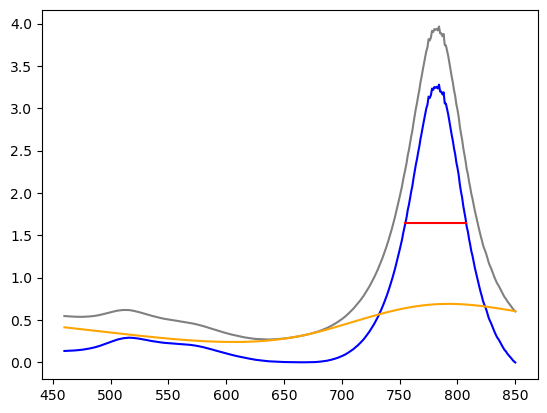

In [831]:
plt.plot(df_filtered, color='grey')
plt.plot(df_baselinecorr.loc[start_lambda:end_lambda,col], color='blue' )
plt.plot(baselines.loc[start_lambda:end_lambda,col], color='orange')
plt.plot([left, right],[hm, hm], color='red')

In [832]:
# get baselines for entire kinetic. This will be used in the next cells
df_baselinecorr, baselines = baseline_correction(df, 2000, 0.00003)



In [833]:
length = len(df_baselinecorr.columns)
fig = plt.figure(figsize=(13,35), dpi=300)
counter =1
ncols = 7
start_lambda = 460
end_lambda = 850
FWHM_all = []

for i in df_baselinecorr.columns:
    
    # calculate FWMH
    wavelength = list(df_baselinecorr.loc[start_lambda:end_lambda,i].index)
    intensity = list(df_baselinecorr.loc[start_lambda:end_lambda,i])
    fwhm, hm, right, left  = estimate_fwhm(wavelength, intensity)
    FWHM_all.append(fwhm)
    
    # create sublots
    ax = plt.subplot(int(length/ncols)+1,ncols,counter) # subplot(nrows, ncols, index, **kwargs)
    
    # plot individual spectra
    ax.plot(df.loc[start_lambda:end_lambda,i], color='firebrick')
    ax.plot(df_baselinecorr.loc[start_lambda:end_lambda,i], color='royalblue')
    ax.plot(baselines.loc[start_lambda:end_lambda,i], color='grey')
    ax.plot([left, right],[hm, hm], color='grey')
    
    # make title
    ax.set_title(f'{i}min, FWHM: {fwhm}nm', fontsize='x-small')
    
    counter+=1
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

fig.tight_layout()

# save list of FWHM to file
index = list(range(0,length))
FWHM = pd.DataFrame({'Time (min)': df.columns, 'FWHM': FWHM_all})
FWHM.to_csv(DATA_PATH+f'{sample}_fwhm.csv')
fig.savefig(DESTINATION_DIR_PATH+f'{sample}_FWHM_all.png')